# CS04 - Line congestion and N-1 security on the IEEE 9-bus system

**Problem type:** thermal overload (congestion), security of supply after an outage,
redispatch and nodal prices.
**Source:** Travaux pratiques, case 3, on the official IEEE/WSCC 9-bus data (MATPOWER
`case9.m`: impedances, ratings and generator costs).

## 1. Context
A grid operator does not only check the intact grid. The **N-1 criterion** requires that
the loss of any single element leaves every other element within its limits. Two
conditions make it harder in the Sahel:
* **hot season:** at 45 degC ambient, conductors cool less, so their thermal rating falls.
  We assume ratings **15 % below** the MATPOWER values (assumption, typical order of magnitude);
* **evening peak:** demand **15 % above** the base case.

## 2. Exercise
1. Compute the economic dispatch (cheapest generation, ignoring security).
2. Run the AC load flow of the intact grid. Any overload?
3. Screen all single line outages (N-1) with AC load flows. Which outage overloads which line?
4. Remove the overload by **preventive redispatch** (security-constrained OPF). What does
   it cost, and what do the nodal prices tell us?
5. Is the grid now N-1 secure in **voltage** as well? If not, what is needed?
6. When does reinforcing the line become better than redispatching?

## 3. Theory
* **Economic dispatch / DC optimal power flow (DC-OPF):** minimise
  $\sum_g (c_{2,g} P_g^2 + c_{1,g} P_g)$ subject to the power balance at each bus and the
  linearised line flows $P_\ell = (\theta_i - \theta_k)/x_\ell \le$ rating.
* **Security-constrained OPF (SC-OPF):** the same, plus the post-outage flows for every
  contingency $c$: $P_\ell^{(c)} = P_\ell + \mathrm{LODF}_{\ell,c}\,P_c \le$ rating
  (line outage distribution factors).
* **Locational marginal price (LMP):** the dual variable of the power balance at a bus:
  the cost of one more MWh **there**. Without congestion all LMPs are equal; congestion
  separates them. The spread is the economic signal for reinforcement.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pscs").exists())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import pypsa
import matplotlib.pyplot as plt

import pscs
from pscs.kpi import run_pf, kpis, branch_table
from pscs.plotting import SERIES, CRITICAL, GOOD, WARNING, INK2, MUTED, save, limit_line

DATA, FIG, TAB = pscs.setup()
DERATE, GROWTH = 0.85, 1.15
RADIAL = ["L1-4", "L3-6", "L8-2"]          # generator step-up connections (outage = unit trip)


def scenario(rating_overrides=None):
    """IEEE 9-bus in hot-season conditions at the evening peak."""
    n = pypsa.Network(DATA / "networks" / "ieee9")
    n.lines["s_nom"] *= DERATE
    n.loads[["p_set", "q_set"]] *= GROWTH
    for ln, s in (rating_overrides or {}).items():
        n.lines.loc[ln, "s_nom"] = s
    return n

n = scenario()
C0 = 150 + 600 + 335                          # constant cost terms c0 of case9 ($/h)
pd.concat([n.lines[["bus0", "bus1", "x", "s_nom"]],
           pd.Series(n.lines.s_nom / DERATE, name="MATPOWER rating")], axis=1)

,bus0,bus1,x,s_nom,MATPOWER rating
name,,,,,
L1-4,1,4,68.5584,212.5,250.0
L4-5,4,5,109.5030,212.5,250.0
L5-6,5,6,202.3425,127.5,150.0
L3-6,3,6,69.7486,255.0,300.0
L6-7,6,7,119.9772,127.5,150.0
L7-8,7,8,85.6980,212.5,250.0
L8-2,8,2,74.3906,212.5,250.0
L8-9,8,9,191.6303,212.5,250.0
L9-4,9,4,101.1713,212.5,250.0


## 4. Economic dispatch (question 1)
**PyPSA detail (version 1.x):** a generator with a numeric `p_set` is held at that value
by `n.optimize()`. The MATPOWER dispatch is stored in `p_set`, so we clear it first.

In [2]:
def optimise(n, security=False):
    n.generators["p_set"] = np.nan
    opts = dict(solver_name="highs", solver_options={"output_flag": False})
    if security:
        outages = [l for l in n.lines.index if l not in RADIAL]
        n.optimize.optimize_security_constrained(branch_outages=outages, **opts)
    else:
        n.optimize(**opts)
    return n.generators_t.p.iloc[0].copy(), n.objective + C0, n.buses_t.marginal_price.iloc[0].copy()

ed, cost_ed, lmp_ed = optimise(scenario())
print(f"Economic dispatch: {ed.round(1).to_dict()}  cost {cost_ed:.0f} $/h  "
      f"LMP {lmp_ed.min():.2f}-{lmp_ed.max():.2f} $/MWh")

Economic dispatch: {'G1': 101.4, 'G2': 153.5, 'G3': 107.3}  cost 6429 $/h  LMP 27.30-27.30 $/MWh


## 5. AC check of the intact grid (question 2)

In [3]:
def ac(dispatch, outage=None, overrides=None, extra=None):
    m = scenario(overrides)
    m.generators["p_set"] = dispatch.values          # slack G1 also covers the AC losses
    if outage:
        m.lines.loc[outage, "active"] = False
    if extra:
        extra(m)
    run_pf(m)
    return m

intact = ac(ed)
bt = branch_table(intact)
print("max loading %.1f %% on %s, min voltage %.3f p.u." %
      (bt["loading (%)"].max(), bt["loading (%)"].idxmax(), intact.buses_t.v_mag_pu.iloc[0].min()))
bt[["from", "to", "P_from (MW)", "|S| (MVA)", "rating (MVA)", "loading (%)"]].round(1)

max loading 72.5 % on L8-2, min voltage 0.984 p.u.


,from,to,P_from (MW),|S| (MVA),rating (MVA),loading (%)
name,,,,,,
L1-4,1,4,106.5,113.4,212.5,53.4
L4-5,4,5,41.8,45.5,212.5,21.4
L5-6,5,6,-62.0,65.2,127.5,51.1
L3-6,3,6,107.3,107.7,255.0,42.3
L6-7,6,7,43.8,50.2,127.5,39.4
L7-8,7,8,-71.4,73.0,212.5,34.4
L8-2,8,2,-153.5,154.2,212.5,72.5
L8-9,8,9,81.7,81.8,212.5,38.5
L9-4,9,4,-64.1,76.2,212.5,35.9


## 6. N-1 screening with AC load flows (question 3)

In [4]:
def n1(dispatch, overrides=None):
    rows = []
    for out in [l for l in scenario().lines.index if l not in RADIAL]:
        m = ac(dispatch, out, overrides)
        b = branch_table(m).drop(out)
        v = m.buses_t.v_mag_pu.iloc[0]
        rows.append({"outage": out, "worst line": b["loading (%)"].idxmax(),
                     "worst loading (%)": b["loading (%)"].max(),
                     "min |V| (p.u.)": v.min(), "bus": v.idxmin()})
    return pd.DataFrame(rows).set_index("outage")

n1_ed = n1(ed)
n1_ed.to_csv(TAB / "cs04_n1_economic_dispatch.csv")
n1_ed.round(3)

,worst line,worst loading (%),min |V| (p.u.),bus
outage,,,,
L4-5,L5-6,87.393,0.909,5
L5-6,L6-7,84.310,0.947,5
L6-7,L5-6,84.768,0.962,7
L7-8,L6-7,95.906,0.952,7
L8-9,L5-6,112.720,0.916,9
L9-4,L6-7,97.432,0.751,9


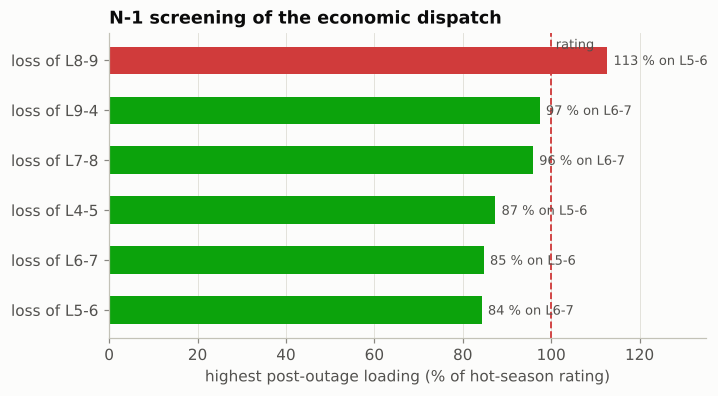

In [5]:
def n1_chart(table, title, path):
    fig, ax = plt.subplots(figsize=(7.0, 3.6))
    t = table.sort_values("worst loading (%)")
    y = np.arange(len(t))
    cols = [CRITICAL if v > 100 else GOOD for v in t["worst loading (%)"]]
    ax.barh(y, t["worst loading (%)"], color=cols, height=0.55)
    for yi, (out, r) in zip(y, t.iterrows()):
        ax.annotate(f"{r['worst loading (%)']:.0f} % on {r['worst line']}", (r["worst loading (%)"], yi),
                    xytext=(4, -3), textcoords="offset points", fontsize=8.5, color=INK2)
    limit_line(ax, 100, "rating", color=CRITICAL, axis="x")
    ax.set_yticks(y); ax.set_yticklabels([f"loss of {o}" for o in t.index])
    ax.set_xlim(0, 135); ax.set_xlabel("highest post-outage loading (% of hot-season rating)")
    ax.set_title(title); ax.grid(axis="y", visible=False)
    save(fig, path)
    return fig

n1_chart(n1_ed, "N-1 screening of the economic dispatch", FIG / "cs04_n1_economic.png")

**Reading:** the intact grid is fine, but the **loss of line 8-9 overloads line 5-6**
(about 113 % of its hot-season rating): the economic dispatch is **not N-1 secure**. The
operator must act **before** the outage (preventive redispatch), because a 113 % overload
would trip line 5-6 by protection and cascade.

## 7. Preventive redispatch with the security-constrained OPF (question 4)

In [6]:
sc, cost_sc, lmp_sc = optimise(scenario(), security=True)
disp = pd.DataFrame({"economic dispatch (MW)": ed, "secure dispatch (MW)": sc})
disp["change (MW)"] = disp.iloc[:, 1] - disp.iloc[:, 0]
print(f"Cost of security: {cost_sc - cost_ed:.1f} $/h  ({100 * (cost_sc / cost_ed - 1):.2f} %)")
disp.round(1)

Cost of security: 54.1 $/h  (0.84 %)


,economic dispatch (MW),secure dispatch (MW),change (MW)
name,,,
G1,101.4,119.8,18.4
G2,153.5,142.7,-10.9
G3,107.3,99.8,-7.5


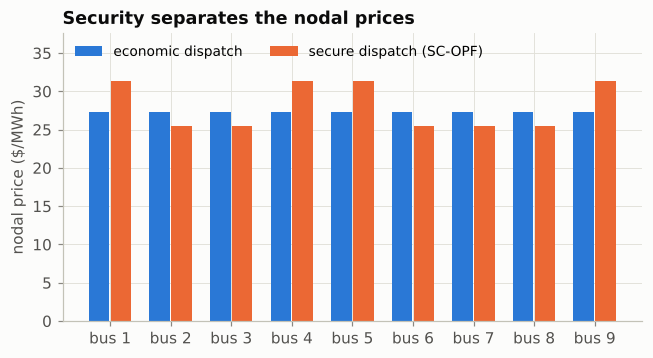

In [7]:
prices = pd.DataFrame({"economic dispatch": lmp_ed, "secure dispatch": lmp_sc})
prices.to_csv(TAB / "cs04_lmp.csv")
fig, ax = plt.subplots(figsize=(6.8, 3.4))
x = np.arange(len(prices))
ax.bar(x - 0.18, prices["economic dispatch"], 0.34, color=SERIES[0], label="economic dispatch")
ax.bar(x + 0.18, prices["secure dispatch"], 0.34, color=SERIES[1], label="secure dispatch (SC-OPF)")
ax.set_xticks(x); ax.set_xticklabels([f"bus {b}" for b in prices.index])
ax.set_ylabel("nodal price ($/MWh)"); ax.set_ylim(0, prices.max().max() * 1.2)
ax.set_title("Security separates the nodal prices")
ax.legend(loc="upper left", ncol=2)
save(fig, FIG / "cs04_lmp.png")
fig

In [8]:
n1_sc = n1(sc)
n1_sc.to_csv(TAB / "cs04_n1_secure_dispatch.csv")
n1_chart(n1_sc, "N-1 screening after preventive redispatch (DC SC-OPF)", FIG / "cs04_n1_secure.png")
n1_sc.round(3)

,worst line,worst loading (%),min |V| (p.u.),bus
outage,,,,
L4-5,L5-6,87.418,0.908,5
L5-6,L6-7,78.365,0.950,5
L6-7,L5-6,78.941,0.962,7
L7-8,L6-7,95.921,0.951,7
L8-9,L5-6,98.656,0.920,9
L9-4,L6-7,106.100,0.747,9


**Reading:** the SC-OPF moves generation away from G2 (which pushes power through 8-9 and
5-6 after the outage) towards G1. The extra cost is small (about 54 $/h, under 1 %), the
post-outage loading of line 5-6 drops from 113 % to about 99 % (checked with the full AC
model), and nodal prices now differ by bus: the **price spread** is the value of transport
capacity on that corridor.

**But the AC re-check finds a new violation:** after the loss of line 9-4, line 6-7 reaches
about 106 %. The DC optimiser predicted it would be fine. The cause is the **voltage**
collapse at bus 9 in that outage (next section): low voltage means more current for the
same power, and large reactive flows that a DC model ignores.

## 8. Security is also about voltage (question 5)
The SC-OPF is a **DC** model: it knows nothing about voltages. The N-1 table shows that the
**loss of line 9-4** leaves bus 9 (125 MW x 1.15) fed by line 8-9 alone, and its voltage
collapses to about 0.75 p.u. We size the reactive support needed at bus 9 after this outage.

In [9]:
def cap9(q):
    return lambda m: m.add("ShuntImpedance", "cap9", bus="9", b=q / 345**2)

lo, hi = 0.0, 300.0
for _ in range(30):
    mid = (lo + hi) / 2
    v9 = ac(sc, "L9-4", extra=cap9(mid)).buses_t.v_mag_pu.iloc[0]["9"]
    lo, hi = (mid, hi) if v9 < 0.95 else (lo, mid)
q_cap9 = hi
v9_before = ac(sc, "L9-4").buses_t.v_mag_pu.iloc[0]["9"]
print(f"After the loss of line 9-4: V9 = {v9_before:.3f} p.u.; "
      f"{q_cap9:.0f} MVAr of reactive support at bus 9 restores 0.95 p.u.")

After the loss of line 9-4: V9 = 0.747 p.u.; 62 MVAr of reactive support at bus 9 restores 0.95 p.u.


In [10]:
fixed = ac(sc, "L9-4", extra=cap9(q_cap9))
bf = branch_table(fixed).drop("L9-4")
print(f"Secure dispatch + {q_cap9:.0f} MVAr switched in at bus 9 after the loss of 9-4: "
      f"worst loading {bf['loading (%)'].max():.1f} % ({bf['loading (%)'].idxmax()}), "
      f"V9 = {fixed.buses_t.v_mag_pu.iloc[0]['9']:.3f} p.u.")

Secure dispatch + 62 MVAr switched in at bus 9 after the loss of 9-4: worst loading 98.5 % (L6-7), V9 = 0.950 p.u.


With the reactive support switched in after the outage, line 6-7 also returns below its
rating: the flow problem of section 7 was in fact a **voltage** problem.

**Lesson:** a dispatch can be secure for **flows** and insecure for **voltage**. Real
operators therefore run **AC** contingency analysis after any DC-based optimisation, and
plan reactive reserves (capacitor banks, SVC, generator reactive margin) for the critical
outages.

## 9. Redispatch or reinforce? (question 6)
Reconductoring line 5-6 with a high-temperature conductor (assumed hot-season rating
200 MVA) removes the thermal constraint: the economic dispatch becomes N-1 secure **for
flows**. The reactive support at bus 9 (section 8) is still needed: reinforcing a line does
not cure a voltage problem elsewhere.

In [11]:
n1_reinf = n1(ed, overrides={"L5-6": 200.0})
print("economic dispatch with reinforced 5-6: worst N-1 loading %.0f %%"
      % n1_reinf["worst loading (%)"].max())
hours = 600                                   # hot-season evening-peak hours per year (assumption)
extra = cost_sc - cost_ed
print(f"Redispatch cost if this situation lasts {hours} h/year: {extra * hours / 1e3:.0f} k$/year")

economic dispatch with reinforced 5-6: worst N-1 loading 97 %
Redispatch cost if this situation lasts 600 h/year: 32 k$/year


**Decision logic:** redispatch costs about the hourly security cost times the number of hours
the constraint is active. Reinforcement is a one-off investment (annualised over about 40
years). As long as the yearly redispatch cost stays well below the annualised investment,
redispatch is the rational choice; the LMP spread and its growth with demand tell the
planner when to switch.

**What to say:** "The IEEE 9-bus system shows that a cheap dispatch can be unsafe: losing
line 8-9 at a hot-season evening peak overloads line 5-6 by about 13 %. A
security-constrained OPF removes the overload for a small extra cost and reveals a nodal
price spread. The AC re-check exposes a voltage collapse at bus 9 after the loss of line
9-4 (0.75 p.u.), which also overloads line 6-7: about 60 MVAr of switched reactive support
at bus 9 is needed to make the plan fully N-1 secure. Reinforcement becomes worthwhile only if the
congestion becomes frequent."

In [12]:
pscs.save_summary("cs04", {
    "ed": ed.to_dict(), "sc": sc.to_dict(), "cost_ed": cost_ed, "cost_sc": cost_sc,
    "security_cost_per_h": cost_sc - cost_ed,
    "lmp_ed": [lmp_ed.min(), lmp_ed.max()], "lmp_sc": [lmp_sc.min(), lmp_sc.max()],
    "intact_max_loading": bt["loading (%)"].max(),
    "n1_worst_ed": n1_ed["worst loading (%)"].max(), "n1_worst_ed_outage": n1_ed["worst loading (%)"].idxmax(),
    "n1_worst_ed_line": n1_ed.loc[n1_ed["worst loading (%)"].idxmax(), "worst line"],
    "n1_worst_sc": n1_sc["worst loading (%)"].max(),
    "v9_after_L94": v9_before, "q_cap9": q_cap9,
    "fixed_worst_loading": bf["loading (%)"].max(),
    "n1_worst_reinforced": n1_reinf["worst loading (%)"].max(),
    "yearly_redispatch_k$": extra * hours / 1e3,
})